<a href="https://colab.research.google.com/github/lydiateinfalt/Agent-Based-Modeling-Migration-and-Cognition/blob/main/Experiment3_Emergent_Divergence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 3 – Poverty trap: what makes agents diverge?
Start condition: every agent has aspiration > 5 and ability < 5, so the whole population begins trapped (red, involuntary non-migrant). Diaspora signal is 0 and network strength 0.4 in all runs, 100 seeds, 6000 ticks (1 tick = 1 day).

Two BehaviorSpace exports are used:
* **Series export (3a)**: population metrics every 10 ticks, including the emergence metrics (SD of financial ability, agents at the floor, never / in-zone / fell-back typology, neighbour contact).
* **Agent export (3d)**: one row per agent at ticks 0, 1000, 3000 and 6000, including the hidden trait `ability-growth-potential`.

The question is *why* agents with identical social settings end up in very different places, and whether that divergence is path dependence, luck or a built-in agent trait.

In [1]:
# Google Colab: mount Drive and move to the folder that holds the BehaviorSpace exports.
# Outside Colab this cell just reports the current folder, so the notebook runs unchanged.
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    for folder in ('Colab Notebooks', 'Colab_Notebooks'):
        path = f'/content/drive/MyDrive/{folder}/'
        if os.path.isdir(path):
            os.chdir(path); break
except ImportError:
    pass
print('working folder:', os.getcwd())

Mounted at /content/drive
working folder: /content/drive/MyDrive/Colab Notebooks


In [2]:
import os
files = os.listdir('.')
print('Files in current directory:')
for f in sorted(files):
    if f.endswith('.csv'):
        print(f'- {f}')

Files in current directory:
- Diaspora_sweep_v2.csv
- External Shock.csv
- Migration_CognitiveGap Experiment 3-table.csv
- Migration_CognitiveGap Experiment 3a.csv
- Migration_CognitiveGap Experiment 3b.csv
- Migration_CognitiveGap Experiment 3d Poverty Trap High Low Growth.csv


In [3]:
import csv, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
plt.style.use('ggplot')

FILE_SERIES = 'Migration_CognitiveGap Experiment 3a.csv'                                    # population series, every 10 ticks
FILE_AGENTS = 'Migration_CognitiveGap Experiment 3d Poverty Trap High Low Growth.csv'       # agent snapshots with ability-growth-potential
for _n in ('FILE_SERIES', 'FILE_AGENTS'):                                   # accept the underscore spelling that some downloads use
    if not os.path.exists(globals()[_n]) and os.path.exists(globals()[_n].replace(' ', '_')):
        globals()[_n] = globals()[_n].replace(' ', '_')
    elif not os.path.exists(globals()[_n]) and os.path.exists(globals()[_n].replace('_', ' ')):
        globals()[_n] = globals()[_n].replace('_', ' ')

SEED = 'global-seed'
COLORS = ['cyan', 'green', 'yellow', 'red', 'orange']
LABEL  = {'cyan': 'cyan (voluntary non-migrant)', 'green': 'green (voluntary migrant)', 'yellow': 'yellow (acquiescent)',
          'red': 'red (trapped)', 'orange': 'orange (distressed migrant)'}
PLOT   = {'cyan': 'darkturquoise', 'green': 'forestgreen', 'yellow': 'gold', 'red': 'crimson', 'orange': 'darkorange'}

In [4]:
def _num(v):
    try: return float(v)
    except (TypeError, ValueError): return v

def _spreadsheet_blocks(path):
    rows = list(csv.reader(open(path, encoding='utf-8-sig')))
    i_run = next(i for i, r in enumerate(rows) if r and r[0] == '[run number]')
    i_all = next(i for i, r in enumerate(rows) if r and r[0] == '[all run data]')
    hdr = rows[i_all][1:]
    starts = [j for j, h in enumerate(hdr) if h == '[step]']
    L = starts[1] - starts[0] if len(starts) > 1 else len(hdr)
    params = {rows[j][0]: j for j in range(i_run + 1, i_all) if rows[j] and rows[j][0] and not rows[j][0].startswith('[')}
    return rows, i_run, i_all, hdr, L, params

def load_export(path):
    """Series export (spreadsheet or table format) -> one long DataFrame, one row per run and recorded step."""
    rows, i_run, i_all, hdr, L, params = _spreadsheet_blocks(path) if 'Spreadsheet' in ''.join(csv.reader(open(path, encoding='utf-8-sig')).__next__()) else (None,) * 6
    if rows is not None:
        seen, names = {}, []
        for h in hdr[:L]:
            seen[h] = seen.get(h, -1) + 1
            names.append(h if seen[h] == 0 else f'{h}.{seen[h]}')
        names = ['step' if h == '[step]' else h for h in names]
        body = np.array([r[1:] for r in rows[i_all + 1:] if len(r) > 1], dtype=object)
        out = []
        for k in range(len(hdr) // L):
            c0 = k * L
            b = pd.DataFrame(body[:, c0:c0 + L], columns=names).apply(pd.to_numeric, errors='coerce').dropna(subset=['step'])
            b['[run number]'] = int(rows[i_run][1 + c0])
            for p, j in params.items(): b[p] = rows[j][1 + c0]
            out.append(b)
        d = pd.concat(out, ignore_index=True)
        for p in params: d[p] = d[p].map(_num)
        if 'ticks' not in d.columns: d['ticks'] = d['step']
        d = d.drop(columns='step')
    else:
        d = pd.read_csv(path, skiprows=6); d.columns = [c.strip() for c in d.columns]
        if 'ticks' not in d.columns: d = d.rename(columns={'[step]': 'ticks'})
    d = d.drop(columns=[c for c in d.columns if c.endswith('.1') and c[:-2] in d.columns])
    ren = {}
    for c in d.columns:
        s = c.strip()
        if s.startswith('count turtles with [color'):                       ren[c] = s.split('=')[-1].strip(' ]')
        elif s.startswith('ifelse-value any? turtles with [color = orange]'): ren[c] = 'fin-ability-orange'
        elif s == 'mean [asp-economic] of turtles':                         ren[c] = 'mean-asp-economic'
        elif s == 'mean [abil-financial] of turtles':                       ren[c] = 'mean-abil-financial'
        elif s == 'mean [abil-human] of turtles':                           ren[c] = 'mean-abil-human'
        elif s == 'standard-deviation [abil-financial] of turtles':         ren[c] = 'sd-fin'
        elif s == 'standard-deviation [total-ability] of turtles':          ren[c] = 'sd-ability'
        elif s == 'count turtles with [abil-financial <= 0]':               ren[c] = 'fin-floor'
        elif s == 'count turtles with [abil-financial > 5]':                ren[c] = 'fin-above5'
        elif s == 'count turtles with [not ever-migrated?]':                ren[c] = 'never'
        elif s.startswith('count turtles with [ever-migrated? and (migration-status'):     ren[c] = 'in-zone-type'
        elif s.startswith('count turtles with [ever-migrated? and not (migration-status'): ren[c] = 'fell-back'
        elif s.startswith('ifelse-value any? turtles with [ever-migrated?]'):              ren[c] = 'nbr-mig-of-migrants'
        elif s.startswith('ifelse-value any? turtles with [not ever-migrated?]'):          ren[c] = 'nbr-mig-of-never'
    return d.rename(columns=ren)

def load_agents(path):
    """Agent-level snapshots: the last metric is a list of [who total-aspiration total-ability abil-financial abil-human
    migration-status ever-migrated? degree ability-growth-potential] per turtle."""
    rows, i_run, i_all, hdr, L, params = _spreadsheet_blocks(path)
    ic = next(j for j, h in enumerate(hdr[:L]) if h.startswith('[ (list who'))
    it = hdr[:L].index('ticks')
    recs = []
    for k in range(len(hdr) // L):
        c0 = k * L; run = int(rows[i_run][1 + c0])
        for r in rows[i_all + 1:]:
            if len(r) <= 1 + c0 + ic or not r[1 + c0 + ic].strip(): continue
            tk = int(float(r[1 + c0 + it]))
            for m in re.finditer(r'\[([^\[\]]*)\]', r[1 + c0 + ic][1:-1]):
                p = m.group(1).split()
                if len(p) < 9: continue
                recs.append((run, tk, int(float(p[0])), float(p[1]), float(p[2]), float(p[3]), float(p[4]), p[5].strip('"'), p[6] == 'true', int(float(p[7])), float(p[8])))
    return pd.DataFrame(recs, columns='run tick who asp abil fin hum status ever deg g'.split())

d = load_export(FILE_SERIES)
runs = d['[run number]'].nunique()
print(f"series: {len(d):,} rows | {runs} runs | ticks {d.ticks.min():.0f}-{d.ticks.max():.0f} every {np.diff(sorted(d.ticks.unique()))[0]:.0f}")
for p in ['initial-aspiration-level', 'initial-ability-level', 'network-strength', 'diaspora-signal', 'num-turtles']:
    print(f'  {p}: {d[p].unique()}')
T_END = d.ticks.max()
B = d
G = B.groupby('ticks').mean(numeric_only=True)
G['gap'] = G['mean-aspiration-level'] - G['mean-ability-level']
def W(m): return B.pivot_table(index=SEED, columns='ticks', values=m)
U = W('unique-migrants'); CM = W('cumulative-migrations'); EX = W('cumulative-exits')
def boot(x, n=5000):
    x = np.asarray(x, float); rng = np.random.default_rng(0)
    return np.percentile(x[rng.integers(0, len(x), (n, len(x)))].mean(1), [2.5, 97.5])

A = load_agents(FILE_AGENTS)
print(f"agents: {len(A):,} rows | {A.run.nunique()} runs | ticks {sorted(A.tick.unique())} | statuses at tick 0: {A[A.tick==0].status.unique()}")
print('growth potential range:', round(A.g.min(), 3), '-', round(A.g.max(), 3), '(expected 0.5-2.0)')

series: 60,100 rows | 100 runs | ticks 0-6000 every 10
  initial-aspiration-level: ['High']
  initial-ability-level: ['Low']
  network-strength: [0.4]
  diaspora-signal: [0.]
  num-turtles: [200.]
agents: 80,000 rows | 100 runs | ticks [np.int64(0), np.int64(1000), np.int64(3000), np.int64(6000)] | statuses at tick 0: ['involuntary-non-migrant']
growth potential range: 0.5 - 2.0 (expected 0.5-2.0)


## 1. Starting conditions (tick 0)

In [5]:
print('Mean population at tick 0 (colour counts are agents out of 200):')
G.loc[0, ['mean-aspiration-level', 'mean-ability-level', 'gap', 'mean-abil-financial', 'mean-abil-human', 'mobility-zone-share'] + COLORS].round(2)

Mean population at tick 0 (colour counts are agents out of 200):


,0
mean-aspiration-level,8.17
mean-ability-level,2.51
gap,5.66
mean-abil-financial,2.52
mean-abil-human,2.51
mobility-zone-share,0.00
cyan,0.00
green,0.00
yellow,0.00
red,200.00


## 2. Time course: aspiration, ability, the gap and the composition

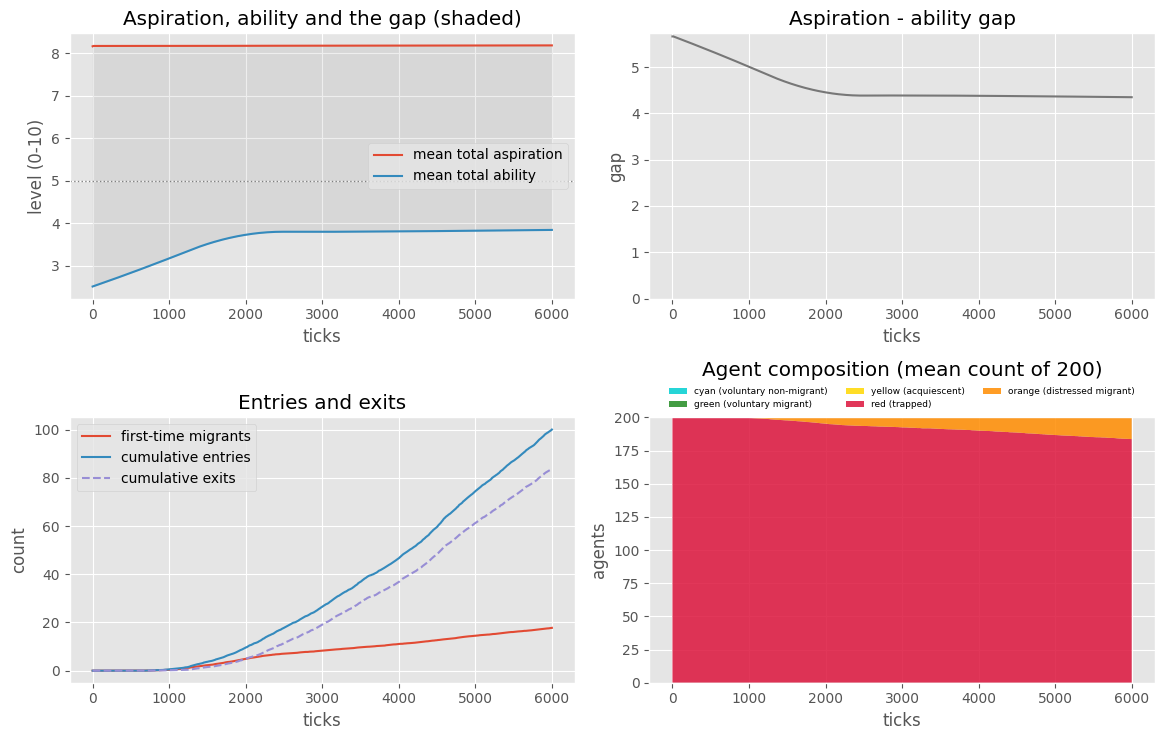

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
ax = axes[0, 0]
ax.plot(G.index, G['mean-aspiration-level'], label='mean total aspiration'); ax.plot(G.index, G['mean-ability-level'], label='mean total ability')
ax.axhline(5, color='grey', ls=':', lw=1); ax.fill_between(G.index, G['mean-ability-level'], G['mean-aspiration-level'], alpha=.12, color='C3')
ax.set_title('Aspiration, ability and the gap (shaded)'); ax.set_ylabel('level (0-10)'); ax.legend(loc='center right')
ax = axes[0, 1]; ax.plot(G.index, G['gap'], color='C3'); ax.set_title('Aspiration - ability gap'); ax.set_ylabel('gap'); ax.set_ylim(0, None)
ax = axes[1, 0]
ax.plot(G.index, G['unique-migrants'], label='first-time migrants'); ax.plot(G.index, G['cumulative-migrations'], label='cumulative entries')
ax.plot(G.index, G['cumulative-exits'], ls='--', label='cumulative exits'); ax.set_title('Entries and exits'); ax.set_ylabel('count'); ax.legend(loc='upper left')
ax = axes[1, 1]
ax.stackplot(G.index, *[G[c] for c in COLORS], colors=[PLOT[c] for c in COLORS], labels=[LABEL[c] for c in COLORS], alpha=.85)
ax.set_ylim(0, 200); ax.set_title('Agent composition (mean count of 200)', pad=30); ax.set_ylabel('agents')
ax.legend(loc='lower center', bbox_to_anchor=(.5, 1.0), ncol=3, fontsize=6.5, frameon=False)
for ax in axes.ravel(): ax.set_xlabel('ticks')
plt.tight_layout(); plt.show()

## 3. Why does mean ability plateau? Human capital versus financial ability
Total ability is the mean of five components. Human capital grows to its cap of 10; financial ability is dragged down for trapped agents. A component's change divided by five is its contribution to the change in mean ability.

human capital reaches its cap (10) at tick 2430; mean ability is within 0.05 of its final value from tick 2340


,start,end,change,contribution to mean ability (change / 5)
mean-abil-human,2.507,10.000,7.493,1.499
mean-abil-financial,2.519,1.694,-0.825,-0.165
mean-ability-level,2.508,3.841,1.334,1.334


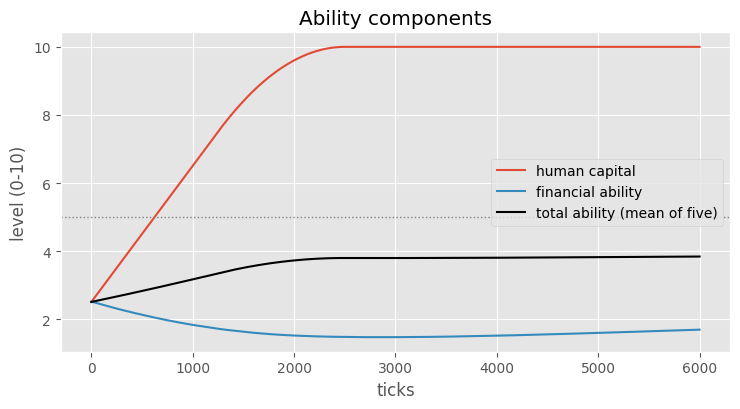

In [7]:
cap = (G['mean-abil-human'] >= 9.99)
t_cap = G.index[cap.values.argmax()] if cap.any() else np.nan
t_plat = G.index[(G['mean-ability-level'] >= G.loc[T_END, 'mean-ability-level'] - 0.05).values.argmax()]
print(f'human capital reaches its cap (10) at tick {t_cap:.0f}; mean ability is within 0.05 of its final value from tick {t_plat:.0f}')
dec = pd.DataFrame({'start': G.loc[0, ['mean-abil-human', 'mean-abil-financial', 'mean-ability-level']], 'end': G.loc[T_END, ['mean-abil-human', 'mean-abil-financial', 'mean-ability-level']]})
dec['change'] = dec.end - dec.start
dec['contribution to mean ability (change / 5)'] = [dec.loc['mean-abil-human', 'change'] / 5, dec.loc['mean-abil-financial', 'change'] / 5, dec.loc['mean-ability-level', 'change']]
display(dec.round(3))
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(G.index, G['mean-abil-human'], label='human capital'); ax.plot(G.index, G['mean-abil-financial'], label='financial ability')
ax.plot(G.index, G['mean-ability-level'], label='total ability (mean of five)', color='k')
ax.axhline(5, color='grey', ls=':', lw=1); ax.set_xlabel('ticks'); ax.set_ylabel('level (0-10)'); ax.set_title('Ability components'); ax.legend(loc='center right')
plt.tight_layout(); plt.show()

## 4. Timing: when do the first agents cross?

tick of the first entry, per run:
count     100.0
mean     1141.0
std       260.0
min       470.0
25%       968.0
50%      1125.0
75%      1282.0
max      1750.0
dtype: float64

ticks to reach k first-time migrants (quartiles; count = runs that reached k):
       1 first-time migrants  5 first-time migrants  10 first-time migrants  \
count                  100.0                  100.0                    98.0   
25%                    968.0                 1720.0                  2778.0   
50%                   1125.0                 1935.0                  3405.0   
75%                   1282.0                 2248.0                  4008.0   

       15 first-time migrants  
count                    81.0  
25%                    4310.0  
50%                    4840.0  
75%                    5430.0  


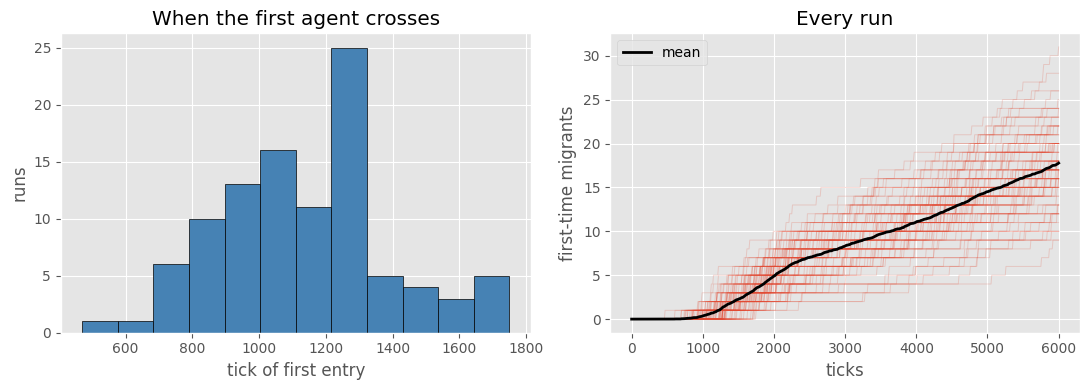

In [8]:
first = U.apply(lambda r: r.index[(r > 0).values.argmax()] if (r > 0).any() else np.nan, axis=1)
print('tick of the first entry, per run:'); print(first.describe().round(0))
def t_reach(row, k): return row.index[(row >= k).values.argmax()] if (row >= k).any() else np.nan
tt = pd.DataFrame({f'{k} first-time migrants': U.apply(lambda r: t_reach(r, k), axis=1) for k in (1, 5, 10, 15)})
print('\nticks to reach k first-time migrants (quartiles; count = runs that reached k):')
print(tt.describe().loc[['count', '25%', '50%', '75%']].round(0))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(first.dropna(), bins=12, edgecolor='black', color='steelblue'); axes[0].set_xlabel('tick of first entry'); axes[0].set_ylabel('runs'); axes[0].set_title('When the first agent crosses')
for _, r in U.iterrows(): axes[1].plot(r.index, r.values, color='C0', alpha=.2, lw=.7)
axes[1].plot(U.columns, U.mean().values, color='k', lw=2, label='mean'); axes[1].set_xlabel('ticks'); axes[1].set_ylabel('first-time migrants'); axes[1].set_title('Every run'); axes[1].legend(loc='upper left')
plt.tight_layout(); plt.show()

## 5. Outcomes at the end of the run (spread across seeds)

,mean,ci_lo,ci_hi,sd,min,max,cv
metric,,,,,,,
unique-migrants,17.770,16.980,18.610,4.194,9.000,31.000,0.236
cumulative-migrations,100.060,93.420,106.920,35.418,37.000,182.000,0.354
cumulative-exits,83.740,77.590,90.170,32.996,26.000,163.000,0.394
orange,16.320,15.530,17.140,4.119,9.000,28.000,0.252
red,183.680,182.860,184.470,4.119,172.000,191.000,0.022
mobility-zone-share,0.082,0.078,0.086,0.021,0.045,0.140,0.252
mean-ability-level,3.841,3.831,3.852,0.056,3.679,3.989,0.014
mean-aspiration-level,8.191,8.176,8.205,0.074,8.029,8.397,0.009


first-time migrants: 17.8 of 200 (8.9%) | entries per first-time migrant: 5.64 | re-entries per run: 82.3 | exits per run: 83.7


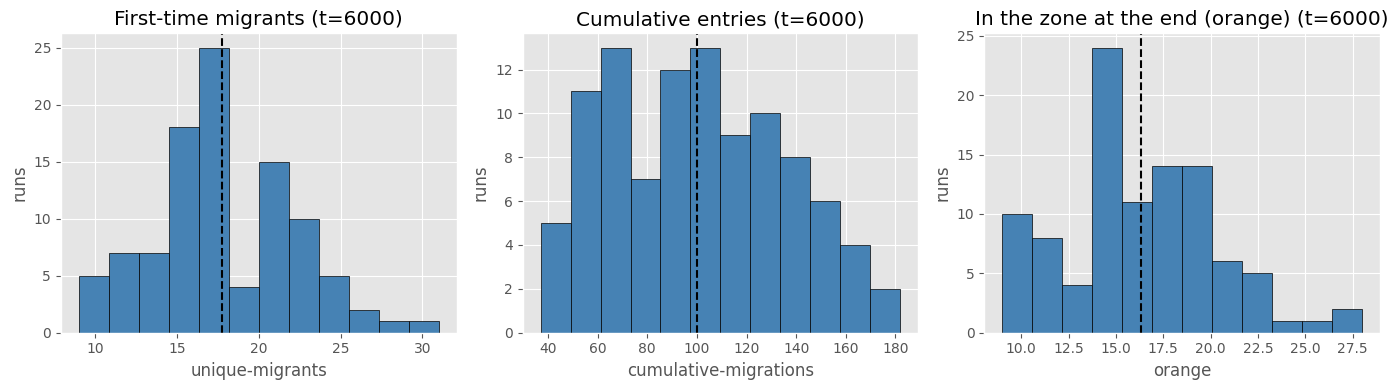

In [9]:
fin = B[B.ticks == T_END].set_index(SEED)
cols = ['unique-migrants', 'cumulative-migrations', 'cumulative-exits', 'orange', 'red', 'mobility-zone-share', 'mean-ability-level', 'mean-aspiration-level']
rows = []
for c in cols:
    x = fin[c]; lo, hi = boot(x)
    rows.append(dict(metric=c, mean=x.mean(), ci_lo=lo, ci_hi=hi, sd=x.std(), min=x.min(), max=x.max(), cv=x.std() / x.mean()))
display(pd.DataFrame(rows).set_index('metric').round(3))
x, c, e = fin['unique-migrants'], fin['cumulative-migrations'], fin['cumulative-exits']
print(f'first-time migrants: {x.mean():.1f} of 200 ({100 * x.mean() / 200:.1f}%) | entries per first-time migrant: {(c / x).mean():.2f} | re-entries per run: {(c - x).mean():.1f} | exits per run: {e.mean():.1f}')
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c_, t in zip(axes, ['unique-migrants', 'cumulative-migrations', 'orange'], ['First-time migrants', 'Cumulative entries', 'In the zone at the end (orange)']):
    ax.hist(fin[c_], bins=12, edgecolor='black', color='steelblue'); ax.axvline(fin[c_].mean(), color='k', ls='--'); ax.set_title(t + f' (t={T_END:.0f})'); ax.set_xlabel(c_); ax.set_ylabel('runs')
plt.tight_layout(); plt.show()

## 6. Churn: entries versus exits

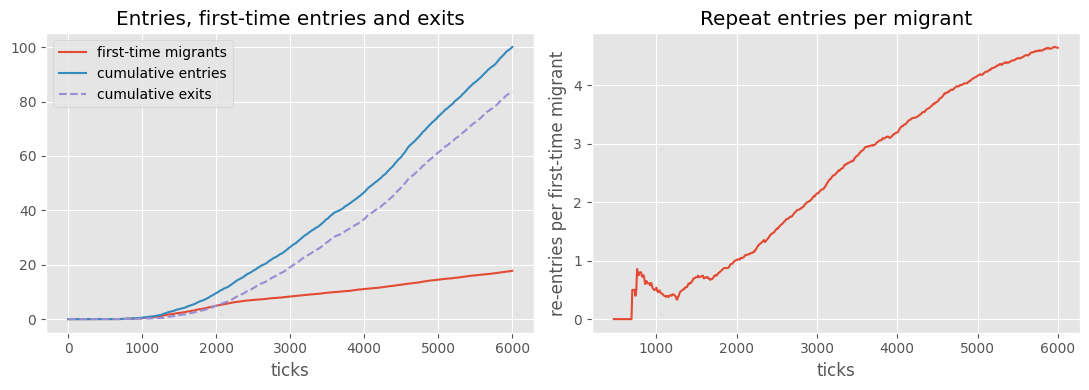

,first-time,entries,exits,in zone now,re-entries / migrant
ticks,,,,,
1000,0.37,0.57,0.20,0.37,0.54
2000,4.92,9.62,4.95,4.67,1.01
3000,8.32,26.55,19.10,7.45,2.15
4000,11.07,46.65,36.77,9.88,3.19
5000,14.51,74.47,61.26,13.21,4.16
6000,17.77,100.06,83.74,16.32,4.64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(U.columns, U.mean(), label='first-time migrants'); axes[0].plot(CM.columns, CM.mean(), label='cumulative entries'); axes[0].plot(EX.columns, EX.mean(), ls='--', label='cumulative exits')
axes[0].set_xlabel('ticks'); axes[0].set_title('Entries, first-time entries and exits'); axes[0].legend(loc='upper left')
rp = ((CM - U) / U.replace(0, np.nan)).mean(); axes[1].plot(rp.index, rp.values); axes[1].set_xlabel('ticks'); axes[1].set_ylabel('re-entries per first-time migrant'); axes[1].set_title('Repeat entries per migrant')
plt.tight_layout(); plt.show()
chk = [t for t in (1000, 2000, 3000, 4000, 5000, T_END) if t in U.columns]
pd.DataFrame({'first-time': U[chk].mean(), 'entries': CM[chk].mean(), 'exits': EX[chk].mean(), 'in zone now': (CM - EX)[chk].mean(),
              're-entries / migrant': ((CM - U) / U.replace(0, np.nan))[chk].mean()}).round(2)

## 7. Divergence inside a run: financial ability spreads out
Every agent starts with similar abilities. The SD of financial ability across the 200 agents, the number stuck at the floor (financial ability ≤ 0) and the number who have escaped (> 5) show how fast a uniform population splits.

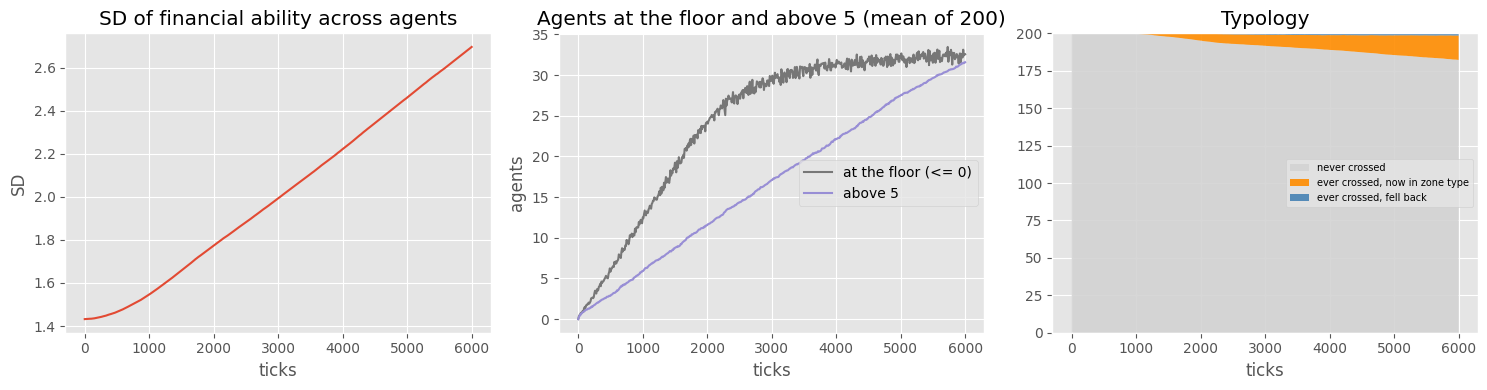

,sd-fin,sd-ability,fin-floor,fin-above5,never,in-zone-type,fell-back
ticks,,,,,,,
0,1.43,0.64,0.00,0.00,200.00,0.00,0.00
500,1.47,0.64,5.83,2.88,199.99,0.01,0.00
1000,1.55,0.65,12.49,5.88,199.63,0.37,0.00
3000,1.99,0.64,29.38,17.09,191.68,7.45,0.87
6000,2.70,0.73,32.55,31.57,182.23,16.32,1.45


Typology is an end-of-run reading: "in zone type" counts agents whose current status is a migrant status, "fell back" those who entered once and have since left.


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(G.index, G['sd-fin']); axes[0].set_title('SD of financial ability across agents'); axes[0].set_ylabel('SD')
axes[1].plot(G.index, G['fin-floor'], label='at the floor (<= 0)', color='C3'); axes[1].plot(G.index, G['fin-above5'], label='above 5', color='C2')
axes[1].set_title('Agents at the floor and above 5 (mean of 200)'); axes[1].legend(loc='center right'); axes[1].set_ylabel('agents')
axes[2].stackplot(G.index, G['never'], G['in-zone-type'], G['fell-back'], labels=['never crossed', 'ever crossed, now in zone type', 'ever crossed, fell back'], colors=['lightgrey', 'darkorange', 'steelblue'], alpha=.9)
axes[2].set_title('Typology'); axes[2].set_ylim(0, 200); axes[2].legend(loc='center right', fontsize=7)
for ax in axes: ax.set_xlabel('ticks')
plt.tight_layout(); plt.show()
chk = [t for t in (0, 500, 1000, 3000, 6000) if t in G.index]
display(G.loc[chk, ['sd-fin', 'sd-ability', 'fin-floor', 'fin-above5', 'never', 'in-zone-type', 'fell-back']].round(2))
print('Typology is an end-of-run reading: "in zone type" counts agents whose current status is a migrant status, "fell back" those who entered once and have since left.')

## 8. Do migrants cluster? Neighbour contact
If social structure mattered, migrants would have more migrant neighbours than agents who never crossed.

In [12]:
f = B[B.ticks == T_END]
print(f"neighbours who have migrated, per agent at t={T_END:.0f}:  migrants {f['nbr-mig-of-migrants'].mean():.2f}  |  never crossed {f['nbr-mig-of-never'].mean():.2f}")
t, p = stats.ttest_rel(f['nbr-mig-of-migrants'], f['nbr-mig-of-never'])
print(f'paired t over {len(f)} runs: t = {t:.2f}, p = {p:.3f}  (no clustering expected: links are made at random and diaspora signal is 0)')

neighbours who have migrated, per agent at t=6000:  migrants 0.23  |  never crossed 0.24
paired t over 100 runs: t = -0.78, p = 0.438  (no clustering expected: links are made at random and diaspora signal is 0)


## 9. Who gets in? Financial ability of the agents in the zone
The mean for orange agents is taken over whoever is in the zone at that tick, so it reflects selection.

In [13]:
chk = [t for t in (1000, 2000, 3000, 4000, 5000, T_END) if t in G.index]
pd.DataFrame({'financial ability, agents in zone': G.loc[chk, 'fin-ability-orange'], 'financial ability, all agents': G.loc[chk, 'mean-abil-financial'], 'agents in zone': G.loc[chk, 'orange']}).round(2)

,"financial ability, agents in zone","financial ability, all agents",agents in zone
ticks,,,
1000,1.40,1.83,0.37
2000,4.70,1.52,4.67
3000,5.48,1.47,7.45
4000,6.11,1.52,9.88
5000,6.66,1.60,13.21
6000,7.24,1.69,16.32


## 10. Agent level: what predicts where an agent ends up?
Agent snapshots at ticks 0, 1000, 3000 and 6000. First a consistency check against the series export, then how well each attribute predicts final financial ability and whether the agent ever crossed.

In [14]:
t0, t6 = A[A.tick == 0].set_index(['run', 'who']), A[A.tick == 6000].set_index(['run', 'who'])
X = t6.copy()
X['fin0'], X['abil0'], X['hum0'] = t0.fin, t0.abil, t0.hum
X['cross'] = X.ever.astype(int)
chk = X.groupby('run').cross.sum()
print(f'check: first-time migrants per run, agent file {chk.mean():.2f} vs series file {fin["unique-migrants"].mean():.2f}  (same worlds if equal)')

def auc(score, y):
    r = stats.rankdata(score); n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def eta2(x, y, q=20):
    b = pd.qcut(x, q, duplicates='drop'); g = y.groupby(b, observed=True)
    return 1 - ((y - g.transform('mean')) ** 2).sum() / ((y - y.mean()) ** 2).sum()

pred = pd.DataFrame({
    'share of variance in final financial ability': {'growth potential': eta2(X.g, X.fin), 'initial total ability': eta2(X.abil0, X.fin),
                                                    'initial financial ability': eta2(X.fin0, X.fin), 'initial human capital': eta2(X.hum0, X.fin), 'number of links': eta2(X.deg.astype(float), X.fin)},
    'AUC for ever crossing': {'growth potential': auc(X.g, X.cross), 'initial total ability': auc(X.abil0, X.cross),
                              'initial financial ability': auc(X.fin0, X.cross), 'initial human capital': auc(X.hum0, X.cross), 'number of links': auc(X.deg.astype(float), X.cross)}})
display(pred.round(3))
print('AUC 0.5 = no information, 1.0 = perfect. Share of variance from 20 quantile bins of each attribute.')

check: first-time migrants per run, agent file 17.77 vs series file 17.77  (same worlds if equal)


,share of variance in final financial ability,AUC for ever crossing
growth potential,0.877,0.923
initial total ability,0.008,0.793
initial financial ability,0.040,0.668
initial human capital,0.001,0.497
number of links,0.000,0.502


AUC 0.5 = no information, 1.0 = perfect. Share of variance from 20 quantile bins of each attribute.


In [15]:
t0, t6 = A[A.tick == 0].set_index(['run', 'who']), A[A.tick == 6000].set_index(['run', 'who'])
X = t6.copy()
X['fin0'], X['abil0'], X['hum0'] = t0.fin, t0.abil, t0.hum
# Calculate the remaining fixed ability components (legal, social, family combined)
X['fixed_other0'] = 5 * t0.abil - t0.fin - t0.hum
X['cross'] = X.ever.astype(int)
chk = X.groupby('run').cross.sum()
print(f'check: first-time migrants per run, agent file {chk.mean():.2f} vs series file {fin["unique-migrants"].mean():.2f}  (same worlds if equal)')

def auc(score, y):
    r = stats.rankdata(score); n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def eta2(x, y, q=20):
    b = pd.qcut(x, q, duplicates='drop'); g = y.groupby(b, observed=True)
    return 1 - ((y - g.transform('mean')) ** 2).sum() / ((y - y.mean()) ** 2).sum()

pred = pd.DataFrame({
    'share of variance in final financial ability': {
        'growth potential': eta2(X.g, X.fin),
        'initial total ability': eta2(X.abil0, X.fin),
        'initial financial ability': eta2(X.fin0, X.fin),
        'initial human capital': eta2(X.hum0, X.fin),
        'initial other fixed (legal/social/family)': eta2(X.fixed_other0, X.fin),
        'number of links': eta2(X.deg.astype(float), X.fin)
    },
    'AUC for ever crossing': {
        'growth potential': auc(X.g, X.cross),
        'initial total ability': auc(X.abil0, X.cross),
        'initial financial ability': auc(X.fin0, X.cross),
        'initial human capital': auc(X.hum0, X.cross),
        'initial other fixed (legal/social/family)': auc(X.fixed_other0, X.cross),
        'number of links': auc(X.deg.astype(float), X.cross)
    }
})
display(pred.round(3))
print('AUC 0.5 = no information, 1.0 = perfect. Share of variance from 20 quantile bins of each attribute.')

check: first-time migrants per run, agent file 17.77 vs series file 17.77  (same worlds if equal)


,share of variance in final financial ability,AUC for ever crossing
growth potential,0.877,0.923
initial total ability,0.008,0.793
initial financial ability,0.040,0.668
initial human capital,0.001,0.497
initial other fixed (legal/social/family),0.001,0.787
number of links,0.000,0.502


AUC 0.5 = no information, 1.0 = perfect. Share of variance from 20 quantile bins of each attribute.


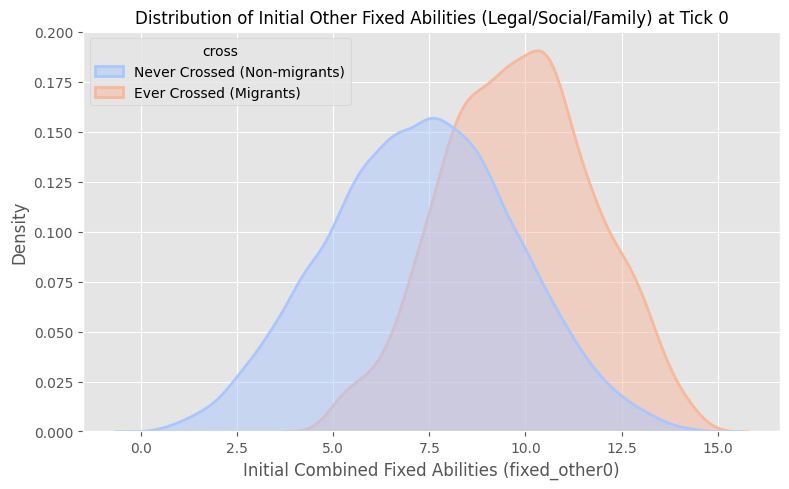

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a plot to visualize the distribution of initial legal/social/family fixed components
fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(data=X, x='fixed_other0', hue='cross', fill=True, common_norm=False, palette='coolwarm', alpha=0.5, linewidth=2, ax=ax)

# Set descriptions and labels
ax.set_title('Distribution of Initial Other Fixed Abilities (Legal/Social/Family) at Tick 0', fontsize=12)
ax.set_xlabel('Initial Combined Fixed Abilities (fixed_other0)')
ax.set_ylabel('Density')

# Modify legend labels for clarity
legend = ax.get_legend()
if legend:
    for text, label in zip(legend.texts, ['Never Crossed (Non-migrants)', 'Ever Crossed (Migrants)']):
        text.set_text(label)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be remo

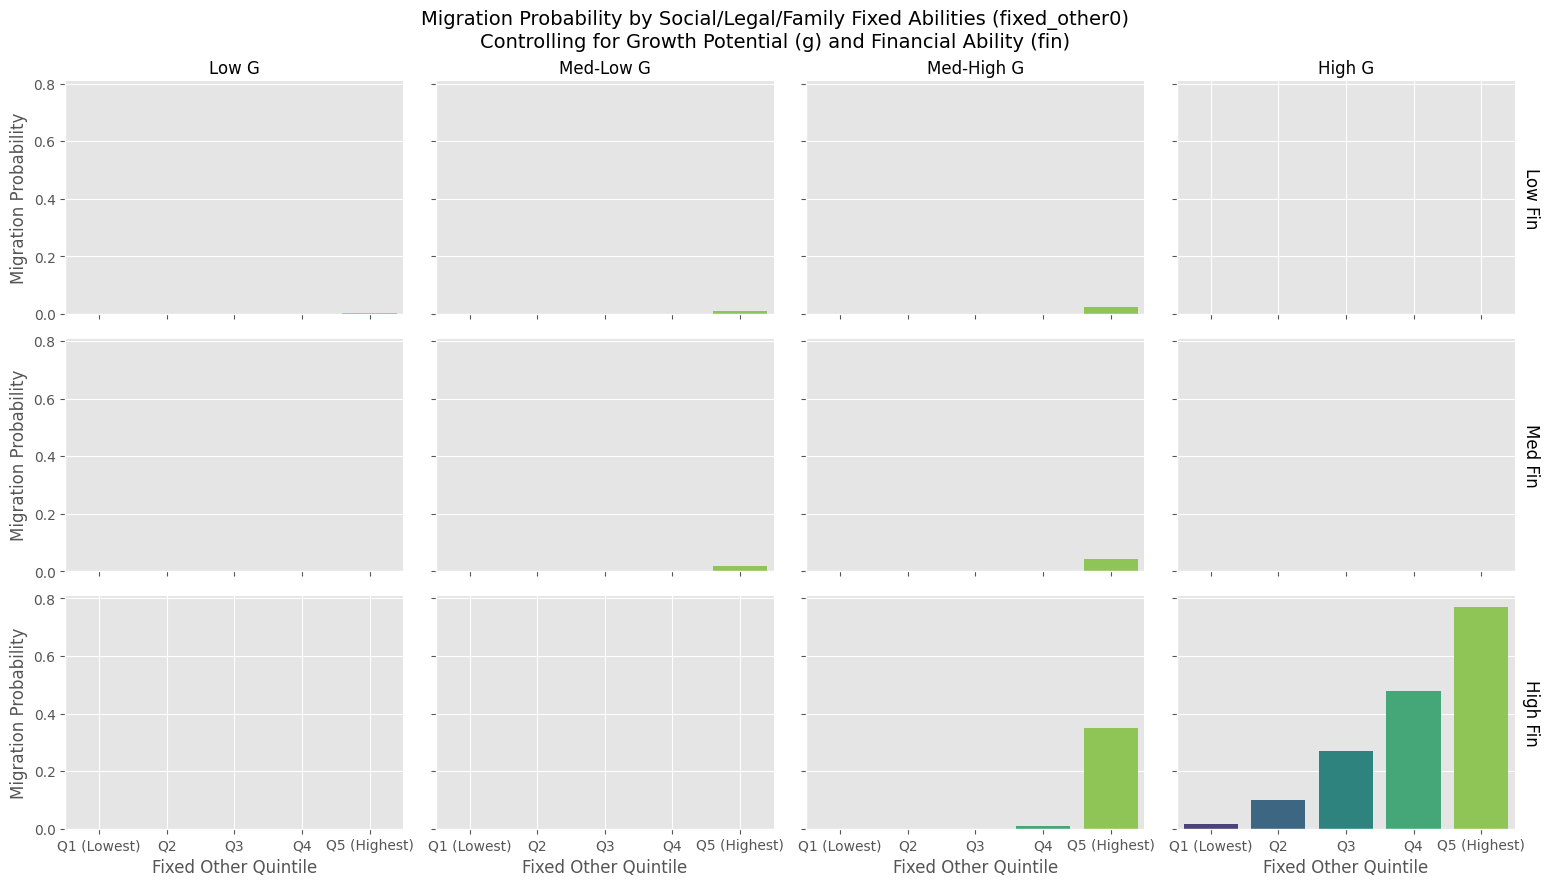

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure required variables are defined
if 'X' not in globals():
    t0, t6 = A[A.tick == 0].set_index(['run', 'who']), A[A.tick == 6000].set_index(['run', 'who'])
    X = t6.copy()
    X['fin0'], X['abil0'], X['hum0'] = t0.fin, t0.abil, t0.hum
    X['fixed_other0'] = 5 * t0.abil - t0.fin - t0.hum
    X['cross'] = X.ever.astype(int)

# Control strategy: Bin 'g' and final 'fin' to keep them constant/comparable
X['g_bin'] = pd.qcut(X['g'], q=4, labels=['Low G', 'Med-Low G', 'Med-High G', 'High G'])
X['fin_bin'] = pd.qcut(X['fin'], q=3, labels=['Low Fin', 'Med Fin', 'High Fin'], duplicates='drop')

# Bin 'fixed_other0' into Quintiles to see its progressive effect
X['fixed_other_quintile'] = pd.qcut(X['fixed_other0'], q=5, labels=['Q1 (Lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (Highest)'])

# Calculate migration probability (mean of 'cross') for each combination
analysis_df = X.groupby(['g_bin', 'fin_bin', 'fixed_other_quintile'], observed=True)['cross'].mean().reset_index()

# Plot the results
grid = sns.FacetGrid(analysis_df, col='g_bin', row='fin_bin', margin_titles=True, height=3, aspect=1.3)
grid.map_dataframe(sns.barplot, x='fixed_other_quintile', y='cross', palette='viridis', order=['Q1 (Lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (Highest)'])

grid.set_titles(col_template="{col_name}", row_template="{row_name}")
grid.set_axis_labels("Fixed Other Quintile", "Migration Probability")
plt.subplots_adjust(top=0.9)
grid.fig.suptitle('Migration Probability by Social/Legal/Family Fixed Abilities (fixed_other0)\nControlling for Growth Potential (g) and Financial Ability (fin)', fontsize=14)

plt.show()

In [18]:
# Calculate and display the Pearson correlation matrix among fixed_other0, g, and final fin
correlation_matrix = X[['fixed_other0', 'g', 'fin']].corr()
display(correlation_matrix.round(3))

,fixed_other0,g,fin
fixed_other0,1.000,-0.005,-0.006
g,-0.005,1.000,0.785
fin,-0.006,0.785,1.000


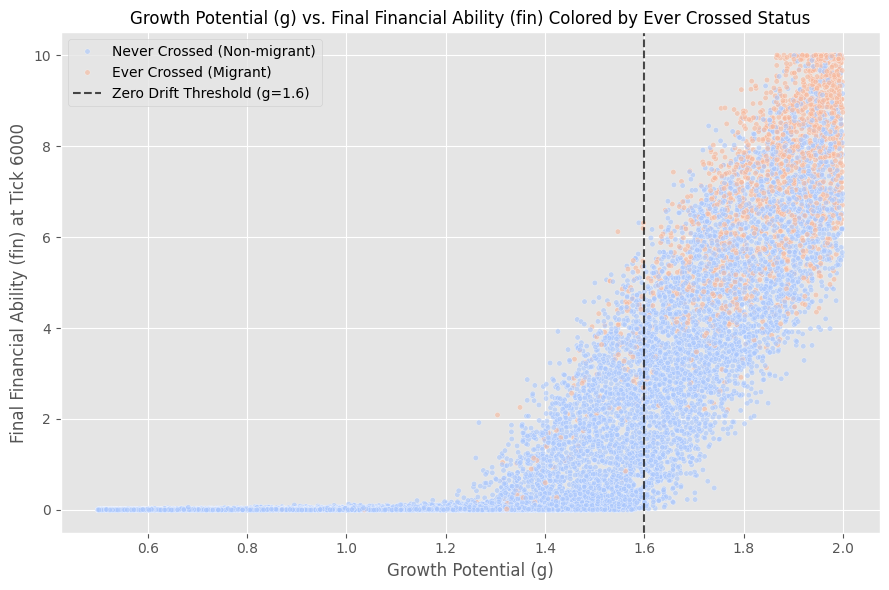

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=X, x='g', y='fin', hue='cross', palette='coolwarm', alpha=0.6, s=15, ax=ax)

ax.axvline(1.6, color='black', linestyle='--', alpha=0.7, label='Zero expected drift threshold (g = 1.6)')
ax.set_title('Growth Potential (g) vs. Final Financial Ability (fin) Colored by Ever Crossed Status', fontsize=12)
ax.set_xlabel('Growth Potential (g)')
ax.set_ylabel('Final Financial Ability (fin) at Tick 6000')

# Relabel the legend for clarity
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=['Never Crossed (Non-migrant)', 'Ever Crossed (Migrant)', 'Zero Drift Threshold (g=1.6)'], loc='upper left')

plt.tight_layout()
plt.show()

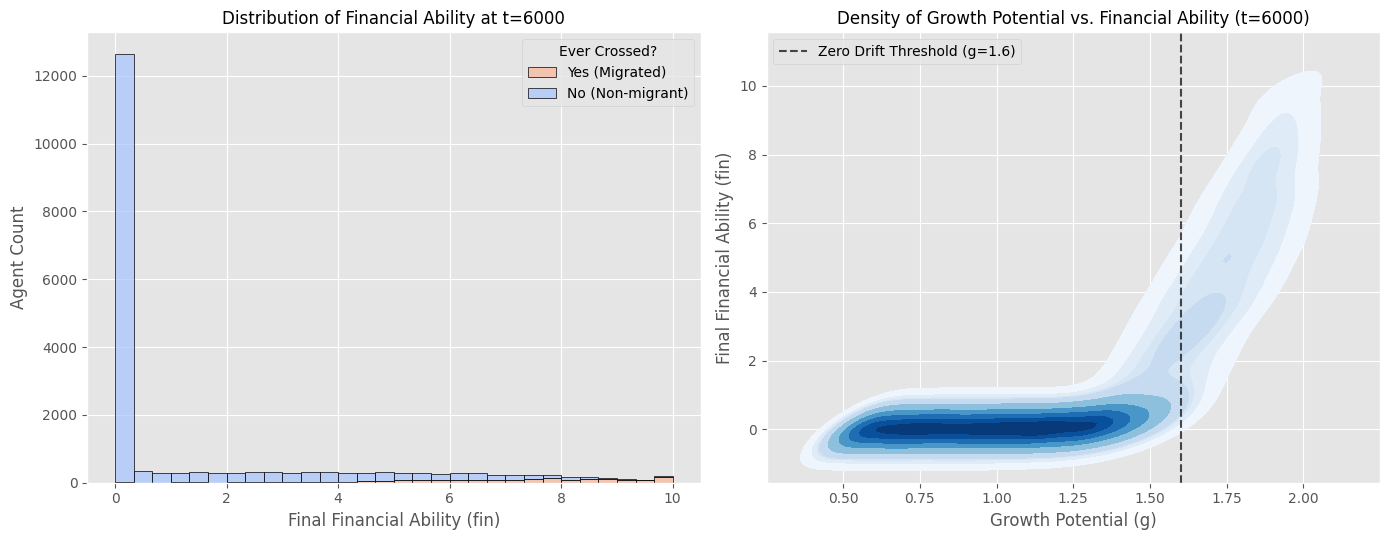

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the agent snapshot DataFrame 'A' is loaded
if 'A' not in globals():
    try:
        A = load_agents(FILE_AGENTS)
    except NameError:
        # In case globals like FILE_AGENTS are also missing, restore them
        import os
        FILE_AGENTS = 'Migration_CognitiveGap Experiment 3d Poverty Trap High Low Growth.csv'
        if not os.path.exists(FILE_AGENTS) and os.path.exists(FILE_AGENTS.replace(' ', '_')):
            FILE_AGENTS = FILE_AGENTS.replace(' ', '_')
        elif not os.path.exists(FILE_AGENTS) and os.path.exists(FILE_AGENTS.replace('_', ' ')):
            FILE_AGENTS = FILE_AGENTS.replace('_', ' ')
        A = load_agents(FILE_AGENTS)

# Filter snapshot data specifically at t=6000
t6000_data = A[A.tick == 6000]

# Set up a side-by-side plot layout
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left Plot: Distribution of Final Financial Ability at t=6000
sns.histplot(data=t6000_data, x='fin', hue='ever', multiple='stack', bins=30, palette='coolwarm', edgecolor='black', alpha=0.75, ax=axes[0])
axes[0].set_title('Distribution of Financial Ability at t=6000', fontsize=12)
axes[0].set_xlabel('Final Financial Ability (fin)')
axes[0].set_ylabel('Agent Count')
axes[0].legend(title='Ever Crossed?', labels=['Yes (Migrated)', 'No (Non-migrant)'])

# Right Plot: Joint KDE of Growth Potential vs. Financial Ability at t=6000
sns.kdeplot(data=t6000_data, x='g', y='fin', cmap='Blues', fill=True, thresh=0.05, ax=axes[1])
axes[1].axvline(1.6, color='black', linestyle='--', alpha=0.7, label='Zero Drift Threshold (g=1.6)')
axes[1].set_title('Density of Growth Potential vs. Financial Ability (t=6000)', fontsize=12)
axes[1].set_xlabel('Growth Potential (g)')
axes[1].set_ylabel('Final Financial Ability (fin)')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

## 11. The tipping point in growth potential
Financial ability for agents in a drag status (all agents here) changes each tick by −0.008 with probability ½, otherwise by +U(0, 0.01) × growth potential. The expected drift is therefore 0.0025 × g − 0.004 per tick, which is zero at g = 1.6.

,agents,mean_final_fin,sd_final_fin,at_floor,above_5,ever_crossed,mean_final_ability
gb,,,,,,,
"(0.499, 0.625]",1628,0.004,0.005,0.397,0.000,0.000,3.515
"(0.625, 0.75]",1670,0.005,0.007,0.375,0.000,0.000,3.487
"(0.75, 0.875]",1662,0.007,0.010,0.333,0.000,0.002,3.514
"(0.875, 1.0]",1680,0.011,0.013,0.292,0.000,0.001,3.511
"(1.0, 1.125]",1673,0.015,0.018,0.234,0.000,0.004,3.512
"(1.125, 1.25]",1660,0.024,0.032,0.172,0.000,0.005,3.498
"(1.25, 1.375]",1668,0.133,0.309,0.115,0.000,0.010,3.513
"(1.375, 1.5]",1656,0.749,0.939,0.037,0.000,0.022,3.676
"(1.5, 1.625]",1633,2.104,1.492,0.007,0.028,0.059,3.931


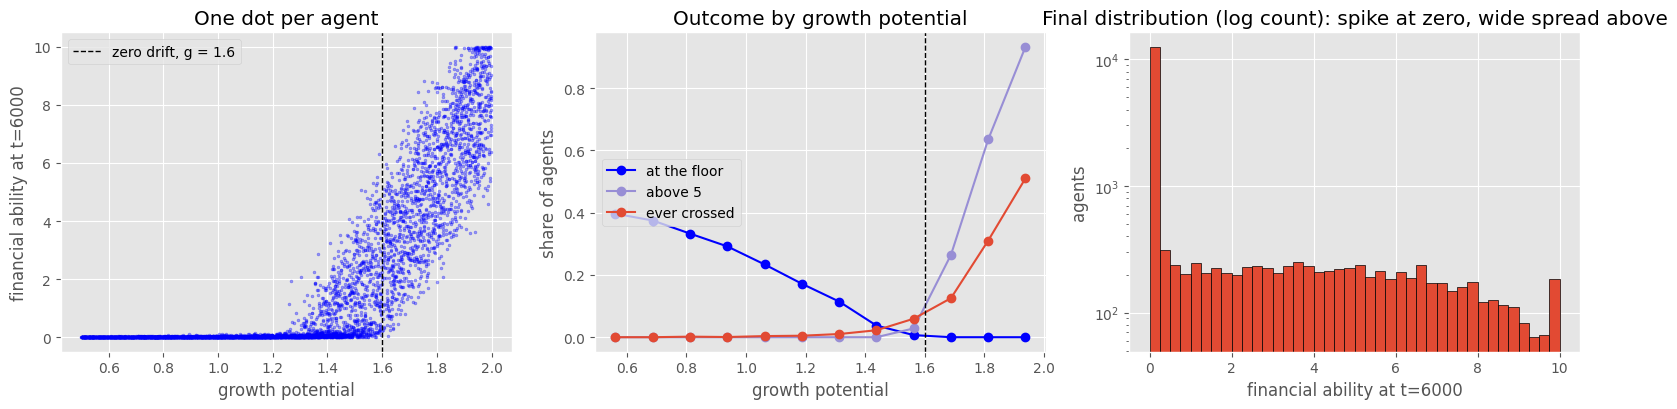

final financial ability: <= 1 for 66.4% of agents, 0 for 16.3%, > 5 for 15.8%


In [21]:
G_STAR = 0.004 / 0.0025
X['gb'] = pd.cut(X.g, np.arange(0.5, 2.0001, 0.125), include_lowest=True)
tab = X.groupby('gb', observed=True).agg(agents=('fin', 'size'), mean_final_fin=('fin', 'mean'), sd_final_fin=('fin', 'std'),
        at_floor=('fin', lambda s: (s <= 0).mean()), above_5=('fin', lambda s: (s > 5).mean()), ever_crossed=('cross', 'mean'), mean_final_ability=('abil', 'mean'))
display(tab.round(3))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
s = X.sample(6000, random_state=0)
axes[0].scatter(s.g, s.fin, s=4, alpha=.35, color='blue'); axes[0].axvline(G_STAR, color='k', ls='--', lw=1, label=f'zero drift, g = {G_STAR:.1f}')
axes[0].set_xlabel('growth potential'); axes[0].set_ylabel('financial ability at t=6000'); axes[0].set_title('One dot per agent'); axes[0].legend(loc='upper left')
mid = [iv.mid for iv in tab.index]
axes[1].plot(mid, tab.at_floor, 'o-', color='blue', label='at the floor'); axes[1].plot(mid, tab.above_5, 'o-', color='C2', label='above 5'); axes[1].plot(mid, tab.ever_crossed, 'o-', color='C0', label='ever crossed')
axes[1].axvline(G_STAR, color='k', ls='--', lw=1); axes[1].set_xlabel('growth potential'); axes[1].set_ylabel('share of agents'); axes[1].set_title('Outcome by growth potential'); axes[1].legend(loc='center left')
axes[2].hist(X.fin, bins=40, edgecolor='black'); axes[2].set_xlabel('financial ability at t=6000'); axes[2].set_ylabel('agents'); axes[2].set_yscale('log'); axes[2].set_title('Final distribution (log count): spike at zero, wide spread above')
plt.tight_layout(); plt.show()
print(f"final financial ability: <= 1 for {(X.fin <= 1).mean():.1%} of agents, 0 for {(X.fin <= 0).mean():.1%}, > 5 for {(X.fin > 5).mean():.1%}")

## 12. How much is luck? Divergence over time and the sensitive band

In [22]:
snap = {t: A[A.tick == t].copy() for t in (1000, 3000, 6000)}
rows = []
for t, y in snap.items():
    y['band'] = pd.cut(y.g, [0.5, 1.0, 1.5, 1.75, 2.0], include_lowest=True)
    gg = y.groupby('band', observed=True).fin.agg(['mean', 'std']); gg['tick'] = t; rows.append(gg.reset_index())
tc = pd.concat(rows).pivot(index='band', columns='tick', values=['mean', 'std']).round(2)
display(tc)
lo, hi = X[(X.g < 1.0)], X[(X.g > 1.9)]
mid_ = X[(X.g > 1.5) & (X.g < 1.8)]
print(f'g < 1.0 : floor {(lo.fin<=0).mean():.0%}, above 5 {(lo.fin>5).mean():.1%}, ever crossed {lo.cross.mean():.1%}   (outcome fixed)')
print(f'g > 1.9 : floor {(hi.fin<=0).mean():.0%}, above 5 {(hi.fin>5).mean():.0%}, ever crossed {hi.cross.mean():.0%}')
print(f'g 1.5-1.8: above 5 {(mid_.fin>5).mean():.0%}, SD of final financial ability {mid_.fin.std():.2f}   (luck-sensitive band)')

mean               std            
tick          1000  3000  6000  1000  3000  6000
band                                            
(0.499, 1.0]  0.83  0.01  0.01  0.97  0.04  0.01
(1.0, 1.5]    1.75  0.72  0.23  1.35  1.01  0.58
(1.5, 1.75]   2.60  2.74  2.97  1.46  1.57  1.82
(1.75, 2.0]   3.22  4.59  6.63  1.47  1.61  1.88

g < 1.0 : floor 35%, above 5 0.0%, ever crossed 0.1%   (outcome fixed)
g > 1.9 : floor 0%, above 5 95%, ever crossed 53%
g 1.5-1.8: above 5 22%, SD of final financial ability 1.98   (luck-sensitive band)


## 13. Path dependence across seeds
Does a world's tick-0 average predict how many agents cross? With 100 seeds the intervals are tighter than before.

In [23]:
i0 = B[B.ticks == 0].set_index(SEED); y = fin['unique-migrants']
rows = []
for c in ['mean-ability-level', 'mean-abil-human', 'mean-abil-financial', 'mean-aspiration-level', 'mean-asp-social']:
    r, p = stats.pearsonr(i0.loc[y.index, c], y); rows.append(dict(start_variable=c, r=r, p=p, r2=r * r))
display(pd.DataFrame(rows).set_index('start_variable').round(3))
gm = X.groupby('run').g.mean()
r, p = stats.pearsonr(gm.loc[y.index], y); print(f'mean growth potential of the 200 agents vs first-time migrants: r = {r:.2f}, p = {p:.3f}')
print(f'final first-time migrants: sd {y.std():.2f} (CV {y.std() / y.mean():.2f}), min {y.min():.0f}, max {y.max():.0f}')

,r,p,r2
start_variable,,,
mean-ability-level,0.243,0.015,0.059
mean-abil-human,0.161,0.110,0.026
mean-abil-financial,0.140,0.164,0.020
mean-aspiration-level,-0.003,0.974,0.000
mean-asp-social,-0.126,0.210,0.016


mean growth potential of the 200 agents vs first-time migrants: r = 0.36, p = 0.000
final first-time migrants: sd 4.19 (CV 0.24), min 9, max 31


## 14. Persistent gap and checkpoint table

In [24]:
chk = [t for t in (0, 500, 1000, 2000, 3000, 4000, 5000, T_END) if t in G.index]
gf = (fin['mean-aspiration-level'] - fin['mean-ability-level'])
print(f'gap at the end across seeds: mean {gf.mean():.2f}, sd {gf.std():.2f}, min {gf.min():.2f}, max {gf.max():.2f}')

pts = [t for t in (500, 1000, 2000, 3000, 4000, 5000, T_END) if t in G.index]
table_cols = ['unique-migrants', 'cumulative-migrations', 'cumulative-exits', 'orange', 'red', 'mean-aspiration-level', 'mean-ability-level', 'gap', 'sd-fin', 'fin-floor', 'fin-above5']
checkpoint_df = G.loc[pts, table_cols].copy()

# Professional column renaming mapping for publication
rename_dict = {
    'unique-migrants': 'Unique Migrants',
    'cumulative-migrations': 'Cum. Entries',
    'cumulative-exits': 'Cum. Exits',
    'orange': 'In Zone (Orange)',
    'red': 'Trapped (Red)',
    'mean-aspiration-level': 'Mean Aspiration',
    'mean-ability-level': 'Mean Ability',
    'gap': 'Aspiration-Ability Gap',
    'sd-fin': 'SD Fin. Ability',
    'fin-floor': 'Fin. Floor (<=0)',
    'fin-above5': 'Fin. Escape (>5)'
}

styled_table = checkpoint_df.rename(columns=rename_dict).style \
    .format("{:.2f}") \
    .set_caption("<b>Table: Key Population Metrics and Composition across Simulation Checkpoints (Mean over 100 Runs)</b>") \
    .set_table_styles([
        {'selector': 'caption', 'props': [('color', '#111111'), ('font-size', '14px'), ('text-align', 'left'), ('margin-bottom', '12px'), ('font-family', 'Georgia, serif'), ('font-weight', 'bold')]},
        {'selector': 'th', 'props': [('background-color', '#f4f6f7'), ('color', '#2c3e50'), ('font-weight', 'bold'), ('border-bottom', '2px solid #2c3e50'), ('border-top', '1px solid #ddd'), ('padding', '10px'), ('font-family', 'Arial, sans-serif')]},
        {'selector': 'td', 'props': [('padding', '10px'), ('border-bottom', '1px solid #e0e0e0'), ('font-family', 'Arial, sans-serif')]}
    ])

display(styled_table)

gap at the end across seeds: mean 4.35, sd 0.10, min 4.09, max 4.63


,Unique Migrants,Cum. Entries,Cum. Exits,In Zone (Orange),Trapped (Red),Mean Aspiration,Mean Ability,Aspiration-Ability Gap,SD Fin. Ability,Fin. Floor (<=0),Fin. Escape (>5)
ticks,,,,,,,,,,,
500,0.01,0.01,0.00,0.01,199.99,8.18,2.83,5.35,1.47,5.83,2.88
1000,0.37,0.57,0.20,0.37,199.63,8.18,3.17,5.01,1.55,12.49,5.88
2000,4.92,9.62,4.95,4.67,195.33,8.18,3.73,4.45,1.77,24.25,11.55
3000,8.32,26.55,19.10,7.45,192.55,8.18,3.80,4.39,1.99,29.38,17.09
4000,11.07,46.65,36.77,9.88,190.12,8.19,3.81,4.38,2.22,31.48,22.14
5000,14.51,74.47,61.26,13.21,186.79,8.19,3.82,4.37,2.46,32.15,27.50
6000,17.77,100.06,83.74,16.32,183.68,8.19,3.84,4.35,2.70,32.55,31.57


## Notes
* **Hidden trait.** `ability-growth-potential` is a per-agent value drawn at setup (about U(0.5, 2.0)) that scales financial recovery. It is not a social or experiential variable, so the divergence documented here comes from built-in heterogeneity amplified by a threshold, not from path dependence. The paper should say so.
* **Ceiling effect.** Everyone starts above the aspiration threshold, so social aspiration cannot change who crosses; diaspora signal was held at 0 here and earlier sweeps showed identical outcomes across arms for the same seed.
* **Luck.** Outcomes are close to fixed for g below about 1.25 (floor) and above about 1.9 (escape); only agents with g near the break-even of 1.6 are sensitive to the random draws.
* The theoretical break-even uses the drift rule in the model code (−0.008 with probability ½, else +U(0,0.01) × g); check it against the current code before quoting it.